In [15]:
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches


In [5]:
# class BrailleGenerator:
#     def __init__(self, img_size=(1448, 1024), scale=10):
#         self.img_size = img_size
#         self.scale = scale
        
#         # Standard Marburg Medium dimensions (mm)
#         self.dot_rad = (1.5 / 2) * self.scale
#         self.px_h_dot = 2.5 * self.scale
#         self.px_v_dot = 2.5 * self.scale
#         self.px_cell_w = 6.0 * self.scale
#         self.px_line_h = 10.0 * self.scale

#     def id_to_bits(self, char_id):
#         """
#         Converts ID (0-62) to 6-bit string, then reverses it for dot mapping.
#         Example: 23 -> '010111' -> reversed -> '111010'
#         """
#         char_id = char_id - 1
#         binary = format(char_id, '06b')
#         return binary[::-1]  # Reverse the string

#     def create_soft_bump(self, radius):
#         size = int(radius * 4) 
#         if size % 2 == 0: size += 1
#         kernel = np.zeros((size, size), dtype=np.float32)
#         center = size // 2
#         for i in range(size):
#             for j in range(size):
#                 d = np.sqrt((i - center)**2 + (j - center)**2)
#                 if d < radius:
#                     kernel[i,j] = np.cos(min(1, d/radius) * (np.pi/2))**1.2
#         return kernel

#     def generate_page(self, allowed_chars=None, margin_mm=20, space_prob=0.2):
#         """
#         Args:
#             allowed_chars: List of ints (0-62). If None, uses all.
#             space_prob: Probability (0-1) of a cell being a blank space.
#         """
#         if allowed_chars is None:
#             allowed_chars = list(range(63))

#         recto_h = np.zeros(self.img_size, dtype=np.float32)
#         verso_h = np.zeros(self.img_size, dtype=np.float32)
        
#         bump = self.create_soft_bump(self.dot_rad)
#         bh, bw = bump.shape
#         offset = bh // 2

#         margin = int(margin_mm * self.scale)
#         cols = int((self.img_size[1] - (2 * margin)) // self.px_cell_w)
#         rows = int((self.img_size[0] - (2 * margin)) // self.px_line_h)

#         for r in range(rows):
#             for c in range(cols):
#                 px = margin + (c * self.px_cell_w)
#                 py = margin + (r * self.px_line_h)
                
#                 # --- Recto (Front) ---
#                 # Randomly decide if this cell is a space
#                 if random.random() > space_prob:
#                     char_id = random.choice(allowed_chars)
#                     bit_str = self.id_to_bits(char_id)
                    
#                     for i, bit in enumerate(bit_str):
#                         if bit == '1':
#                             dx = (i // 3) * self.px_h_dot
#                             dy = (i % 3) * self.px_v_dot
#                             y, x = int(py + dy), int(px + dx)
                            
#                             # Place bump
#                             y1, y2, x1, x2 = y-offset, y+offset+1, x-offset, x+offset+1
#                             if 0 <= y1 and y2 < self.img_size[0] and 0 <= x1 and x2 < self.img_size[1]:
#                                 recto_h[y1:y2, x1:x2] = np.maximum(recto_h[y1:y2, x1:x2], bump)

#                 # --- Verso (Back - Interpoint) ---
#                 # Offset verso by half the cell/line spacing
#                 if random.random() > space_prob:
#                     v_char_id = random.choice(allowed_chars)
#                     v_bit_str = self.id_to_bits(v_char_id)
#                     vx_base = px + (self.px_cell_w / 2)
#                     vy_base = py + (self.px_line_h / 2)

#                     for i, bit in enumerate(v_bit_str):
#                         if bit == '1':
#                             dx = (i // 3) * self.px_h_dot
#                             dy = (i % 3) * self.px_v_dot
#                             y, x = int(vy_base + dy), int(vx_base + dx)
                            
#                             y1, y2, x1, x2 = y-offset, y+offset+1, x-offset, x+offset+1
#                             if 0 <= y1 and y2 < self.img_size[0] and 0 <= x1 and x2 < self.img_size[1]:
#                                 verso_h[y1:y2, x1:x2] = np.maximum(verso_h[y1:y2, x1:x2], bump)

#         # Rendering
#         total_h = (recto_h * 1.0) - (verso_h * 0.45) # Slight depth for verso
#         total_h = cv2.GaussianBlur(total_h, (3, 3), 0)

#         dzdx = cv2.Sobel(total_h, cv2.CV_32F, 1, 0, ksize=3)
#         dzdy = cv2.Sobel(total_h, cv2.CV_32F, 0, 1, ksize=3)
        
#         L = np.array([-0.6, -0.6, 0.8], dtype=np.float32)
#         L /= np.linalg.norm(L)
#         mag = np.sqrt(dzdx**2 + dzdy**2 + 1)
#         nx, ny, nz = -dzdx/mag, -dzdy/mag, 1/mag
        
#         diffuse = (nx * L[0] + ny * L[1] + nz * L[2])
#         final = 0.88 + (diffuse - 1.0) * 0.25
#         final += np.random.normal(0, 0.01, self.img_size)
        
#         return (np.clip(final, 0, 1) * 255).astype(np.uint8)

In [16]:
class BrailleGenerator:
    def __init__(self, img_size=(1448, 1024), scale=10):
        self.img_size = img_size
        self.scale = scale
        
        # Standard Marburg Medium dimensions (mm)
        self.dot_rad = (1.5 / 2) * self.scale
        self.px_h_dot = 2.5 * self.scale
        self.px_v_dot = 2.5 * self.scale
        self.px_cell_w = 6.0 * self.scale
        self.px_line_h = 10.0 * self.scale

    def id_to_bits(self, char_id):
        char_id = max(0, min(62, char_id))
        binary = format(char_id, '06b')
        return binary[::-1] 

    def create_soft_bump(self, radius):
        size = int(radius * 4) 
        if size % 2 == 0: size += 1
        kernel = np.zeros((size, size), dtype=np.float32)
        center = size // 2
        for i in range(size):
            for j in range(size):
                d = np.sqrt((i - center)**2 + (j - center)**2)
                if d < radius:
                    kernel[i,j] = np.cos(min(1, d/radius) * (np.pi/2))**1.4 
        return kernel

    def apply_vignette(self, img, strength=0.2):
        rows, cols = img.shape
        kernel_x = cv2.getGaussianKernel(cols, cols/2)
        kernel_y = cv2.getGaussianKernel(rows, rows/2)
        vignette = kernel_y * kernel_x.T
        vignette = vignette / vignette.max()
        return img * ((1 - strength) + strength * vignette)

    def generate_paper_texture(self):
        texture = np.full(self.img_size, 0.99, dtype=np.float32)
        grain = np.random.normal(0, 0.035, self.img_size)
        small_noise = np.random.normal(0, 0.08, (self.img_size[0]//20, self.img_size[1]//20))
        clouds = cv2.resize(small_noise, (self.img_size[1], self.img_size[0]), interpolation=cv2.INTER_CUBIC)
        clouds = cv2.GaussianBlur(clouds, (15, 15), 0)
        return texture + grain + (clouds * 0.001)

    def apply_perspective_skew(self, img, max_skew_px=60):
        h, w = img.shape
        skew_factor = max_skew_px * (self.scale / 10)
        src_pts = np.float32([[0, 0], [w-1, 0], [0, h-1], [w-1, h-1]])
        
        top_left_x = random.uniform(0, skew_factor)
        top_right_x = random.uniform(-skew_factor, 0)
        bottom_left_x = random.uniform(-skew_factor, 0)
        bottom_right_x = random.uniform(0, skew_factor)
        
        top_y_tilt = random.uniform(0, skew_factor * 0.5)
        bottom_y_tilt = random.uniform(-skew_factor * 0.5, 0)

        dst_pts = np.float32([
            [0 + top_left_x, 0 + top_y_tilt],           
            [w-1 + top_right_x, 0 + top_y_tilt],        
            [0 + bottom_left_x, h-1 + bottom_y_tilt],   
            [w-1 + bottom_right_x, h-1 + bottom_y_tilt] 
        ])
        
        M = cv2.getPerspectiveTransform(src_pts, dst_pts)
        warped = cv2.warpPerspective(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        # FIX: We must return M so we can warp the bounding boxes later!
        return warped, M

    def calculate_lighting(self, total_h, azimuth_deg=225, elevation_deg=45, intensity=0.3):
        """
        azimuth_deg: 0 is Right, 90 is Bottom, 180 is Left, 270 is Top. (225 is Top-Left)
        elevation_deg: 0 is flat on page, 90 is directly above.
        intensity: Depth of shadows (0.1 is soft, 0.5 is harsh).
        """
        dzdx = cv2.Sobel(total_h, cv2.CV_32F, 1, 0, ksize=3)
        dzdy = cv2.Sobel(total_h, cv2.CV_32F, 0, 1, ksize=3)
        
        # Convert angles to 3D Light Vector
        az = np.radians(azimuth_deg)
        el = np.radians(elevation_deg)
        L = np.array([np.cos(el)*np.cos(az), np.cos(el)*np.sin(az), np.sin(el)], dtype=np.float32)
        
        mag = np.sqrt(dzdx**2 + dzdy**2 + 1)
        nx, ny, nz = -dzdx/mag, -dzdy/mag, 1/mag
        
        diffuse = (nx * L[0] + ny * L[1] + nz * L[2])
        return (diffuse - 1.0) * intensity

    def generate_page(self, allowed_chars=None, margin_mm=20, space_prob=0.35, apply_skew=True):
        if allowed_chars is None: allowed_chars = list(range(63))

        recto_h = np.zeros(self.img_size, dtype=np.float32)
        verso_h = np.zeros(self.img_size, dtype=np.float32)
        bump = self.create_soft_bump(self.dot_rad)
        bh, bw = bump.shape
        offset = bh // 2

        margin = int(margin_mm * self.scale)
        cols = int((self.img_size[1] - (2 * margin)) // self.px_cell_w)
        rows = int((self.img_size[0] - (2 * margin)) // self.px_line_h)

        raw_bboxes = [] # To hold [char_id, x1, y1, x2, y2]

        for r in range(rows):
            for c in range(cols):
                px = margin + (c * self.px_cell_w)
                py = margin + (r * self.px_line_h)
                
                # --- Recto (Front) ---
                if random.random() > space_prob:
                    char_id = random.choice(allowed_chars)
                    bit_str = self.id_to_bits(char_id)
                    
                    # Calculate bounding box for this cell (encompassing a 2x3 dot grid)
                    x1 = px - self.dot_rad
                    y1 = py - self.dot_rad
                    x2 = px + self.px_h_dot + self.dot_rad
                    y2 = py + (2 * self.px_v_dot) + self.dot_rad
                    raw_bboxes.append([char_id, x1, y1, x2, y2])
                    
                    for i, bit in enumerate(bit_str):
                        if bit == '1':
                            jitter_x = random.uniform(-0.05, 0.05) * self.scale
                            jitter_y = random.uniform(-0.05, 0.05) * self.scale
                            dx = (i // 3) * self.px_h_dot + jitter_x
                            dy = (i % 3) * self.px_v_dot + jitter_y
                            y, x = int(py + dy), int(px + dx)
                            
                            y1_b, y2_b, x1_b, x2_b = y-offset, y+offset+1, x-offset, x+offset+1
                            if 0 <= y1_b and y2_b < self.img_size[0] and 0 <= x1_b and x2_b < self.img_size[1]:
                                recto_h[y1_b:y2_b, x1_b:x2_b] = np.maximum(recto_h[y1_b:y2_b, x1_b:x2_b], bump)

                # --- Verso (Back - Interpoint) ---
                if random.random() > space_prob:
                    v_char_id = random.choice(allowed_chars)
                    v_bit_str = self.id_to_bits(v_char_id)
                    vx_base = px + (self.px_cell_w / 2)
                    vy_base = py + (self.px_line_h / 2)

                    for i, bit in enumerate(v_bit_str):
                        if bit == '1':
                            dx = (i // 3) * self.px_h_dot
                            dy = (i % 3) * self.px_v_dot
                            y, x = int(vy_base + dy), int(vx_base + dx)
                            
                            y1_b, y2_b, x1_b, x2_b = y-offset, y+offset+1, x-offset, x+offset+1
                            if 0 <= y1_b and y2_b < self.img_size[0] and 0 <= x1_b and x2_b < self.img_size[1]:
                                verso_h[y1_b:y2_b, x1_b:x2_b] = np.maximum(verso_h[y1_b:y2_b, x1_b:x2_b], bump)

        # Rendering
        total_h = (recto_h * 1.0) - (verso_h * 0.40) 
        total_h = cv2.GaussianBlur(total_h, (5, 5), 0) 
        
        # Apply the new parameterized lighting (Azimuth 225° = Top-Left)
        shading = self.calculate_lighting(total_h, azimuth_deg=225, elevation_deg=45, intensity=0.3)
        
        final = self.generate_paper_texture() + shading
        final = self.apply_vignette(final, strength=0.25)
        
        M = None
        if apply_skew:
            final, M = self.apply_perspective_skew(final, max_skew_px=20 * (self.scale/10))

        # Format Annotations to YOLO
        yolo_annotations = []
        img_h, img_w = final.shape

        for box in raw_bboxes:
            char_id, x1, y1, x2, y2 = box
            
            # If skewed, we must warp the 4 corners of the bounding box and find the new min/max
            if M is not None:
                pts = np.float32([[x1, y1], [x2, y1], [x2, y2], [x1, y2]]).reshape(-1, 1, 2)
                warped_pts = cv2.perspectiveTransform(pts, M)
                x1 = warped_pts[:, 0, 0].min()
                y1 = warped_pts[:, 0, 1].min()
                x2 = warped_pts[:, 0, 0].max()
                y2 = warped_pts[:, 0, 1].max()

            # Clip to image boundaries just in case skew pushed them slightly off-canvas
            x1, x2 = max(0, x1), min(img_w, x2)
            y1, y2 = max(0, y1), min(img_h, y2)
            
            w = x2 - x1
            h = y2 - y1
            
            # Skip invalid boxes
            if w <= 0 or h <= 0: continue
            
            xc = x1 + w / 2
            yc = y1 + h / 2
            
            # YOLO Format: label x_center y_center width height (Normalized 0.0 to 1.0)
            yolo_annotations.append(f"{char_id} {xc/img_w:.6f} {yc/img_h:.6f} {w/img_w:.6f} {h/img_h:.6f}")

        final_img_uint8 = (np.clip(final, 0, 1) * 255).astype(np.uint8)
        return final_img_uint8, yolo_annotations

In [17]:
def visualize_braille_annotations(image, yolo_annotations):
    """
    Plots the image and overlays the YOLO-format bounding boxes.
    """
    fig, ax = plt.subplots(1, figsize=(12, 12))
    
    # Display the image
    ax.imshow(image, cmap='gray')
    img_h, img_w = image.shape
    
    for ann in yolo_annotations:
        parts = ann.split()
        char_id = parts[0]
        xc = float(parts[1]) * img_w
        yc = float(parts[2]) * img_h
        w = float(parts[3]) * img_w
        h = float(parts[4]) * img_h
        
        # Calculate top-left corner for matplotlib Rectangle
        x_min = xc - (w / 2)
        y_min = yc - (h / 2)
        
        # Draw the bounding box
        rect = patches.Rectangle(
            (x_min, y_min), w, h, 
            linewidth=1.2, edgecolor='red', facecolor='none', alpha=0.8
        )
        ax.add_patch(rect)
        
        # Optional: Add the label ID text just above the box
        ax.text(x_min, y_min - 2, char_id, color='cyan', fontsize=6, weight='bold')

    plt.axis('off')
    plt.title("Synthetic Braille with Recto Annotations")
    plt.show()

# ==========================================
# Example usage to run in the notebook cell:
# ==========================================
# generator = BrailleGenerator()
# img, annotations = generator.generate_page(space_prob=0.3, apply_skew=True)
# visualize_braille_annotations(img, annotations)

ValueError: too many values to unpack (expected 2)

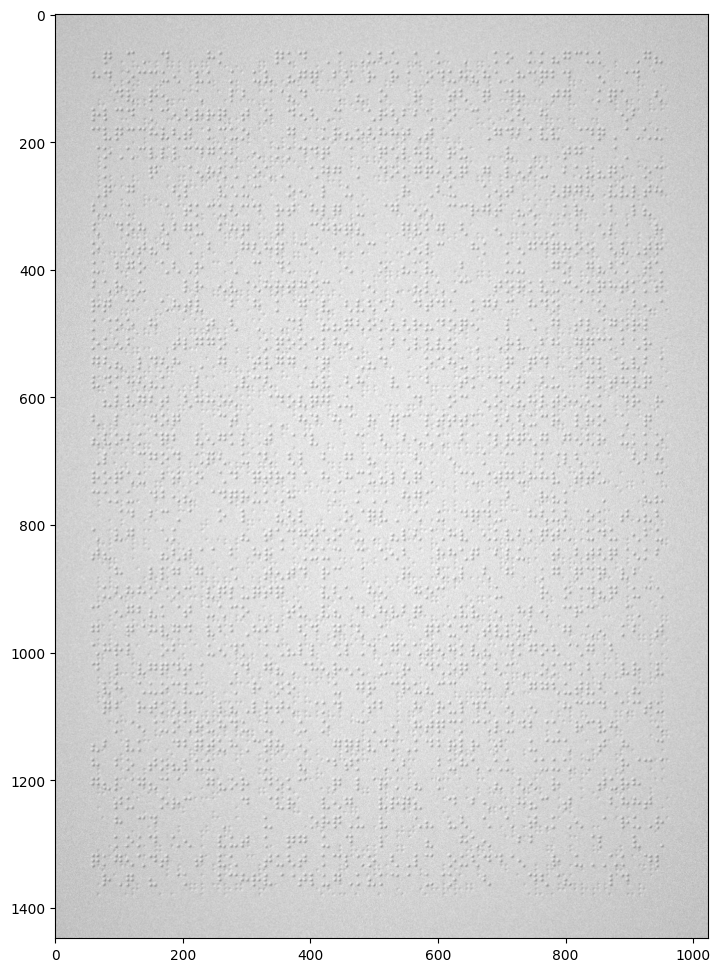

In [ ]:
gen = BrailleGenerator(scale=3)
allowed_chars=[3, 7, 8, 9, 5, 19, 21, 23, 25, 27, 30, 31, 32, 33, 34, 35, 37, 38, 39]
img, annotations = gen.generate_page(allowed_chars=allowed_chars)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(40, 20))
plt.axis("off")
plt.imshow(img)
plt.show()